# Giảm chiều

Dữ liệu nhiều cột thường có những cột thay đổi cùng nhau. Ví dụ điểm toán và điểm lý của một lớp hay tăng giảm cùng nhau: vẽ lên mặt phẳng thì các điểm nằm gần một đường thẳng, nên thay hai số bằng một số (vị trí trên đường đó) chỉ mất ít thông tin. Giảm chiều (dimensionality reduction) làm việc này với dữ liệu nhiều chiều.

Bài này học PCA, cách vẽ dữ liệu nhiều chiều bằng t-SNE, UMAP, và trường hợp phần bị bỏ đi lại chứa đúng thông tin cần để dự đoán.

> **Mục tiêu**
>
> - Tính PCA bằng SVD và dựng lại dữ liệu từ các thành phần.
> - Biết giữ nhiều phương sai chưa chắc giữ được thông tin để dự đoán.
> - Đọc hình t-SNE, UMAP và biết giới hạn của chúng.

## PCA: hướng có phương sai lớn nhất

Phân tích thành phần chính (Principal Component Analysis) tìm các hướng mà dữ liệu trải ra nhiều nhất. Ý tưởng: hướng nào dữ liệu ít thay đổi thì chiếu bỏ đi cũng ít mất thông tin.

Trước hết trừ trung bình để dữ liệu có tâm ở gốc tọa độ. Với ma trận dữ liệu đã trừ trung bình $X \in \R^{n\times d}$, ma trận hiệp phương sai (covariance) là

$$\Sigma = \frac{1}{n}X^\top X.$$

Ô $(j, j)$ trên đường chéo là phương sai của cột $j$, vì hiệp phương sai của một biến với chính nó là phương sai; ô $(j, l)$ đo hai cột cùng tăng giảm với nhau mạnh đến đâu.

Chiếu mỗi điểm lên hướng đơn vị $\mathbf{u}$ cho các số $X\mathbf{u}$, có phương sai $\mathbf{u}^\top\Sigma\,\mathbf{u}$. Ta cần

$$\max_{\mathbf{u}}\ \mathbf{u}^\top\Sigma\,\mathbf{u} \quad\text{thỏa}\quad \lVert\mathbf{u}\rVert = 1.$$

Lời giải là hướng thỏa $\Sigma\mathbf{u} = \lambda\mathbf{u}$: $\mathbf{u}$ là vector riêng (eigenvector) của $\Sigma$, và phương sai thu được chính là trị riêng $\lambda$. Thành phần chính thứ nhất là vector riêng ứng với trị riêng lớn nhất; thành phần thứ hai là vector riêng kế tiếp, tự động vuông góc với thành phần thứ nhất; và cứ thế.



Giữ $k$ thành phần đầu, tỉ lệ phương sai giữ lại (explained variance ratio) là

$$\frac{\lambda_1 + \dots + \lambda_k}{\lambda_1 + \dots + \lambda_d}.$$

Ba thành phần đầu giữ 60%, 25%, 10% thì giữ hai thành phần là giữ 85%. Cách chọn $k$ thường gặp: giữ đủ để đạt khoảng 95% phương sai, hoặc chọn $k$ bằng cross-validation nếu PCA là bước tiền xử lý cho một mô hình khác.

Tính thử trên bốn điểm đã có trung bình bằng 0: $(-2, -1)$, $(-1, -1)$, $(1, 1)$, $(2, 1)$. Ma trận hiệp phương sai là

$$\Sigma = \frac14\begin{pmatrix} 10 & 6 \ 6 & 4\end{pmatrix} = \begin{pmatrix} 2.5 & 1.5 \ 1.5 & 1\end{pmatrix}.$$

Phương trình đặc trưng $\lambda^2 - 3.5\lambda + 0.25 = 0$ cho $\lambda_1 \approx 3.427$, $\lambda_2 \approx 0.073$. Thành phần thứ nhất giữ $3.427/3.5 \approx 97.9\%$ phương sai: bốn điểm gần như nằm trên một đường thẳng. Vector riêng tương ứng có thể chọn $\mathbf{u}_1 \approx (0.851,\ 0.526)$; hướng ngược lại cũng biểu diễn cùng một trục.



Có một cách nhìn tương đương: trong các phép chiếu tuyến tính trực giao xuống $k$ chiều, PCA là phép chiếu làm **tổng bình phương khoảng cách tái tạo** nhỏ nhất. Giữ nhiều phương sai nhất và mất ít thông tin nhất là cùng một bài toán.



**Hỏi nhanh.** Dữ liệu hai chiều đã trừ trung bình có ma trận hiệp phương sai $\Sigma$ với hai trị riêng 4 và 1. Chiếu lên PC1 thì giữ được bao nhiêu phần phương sai, và tọa độ trên PC1 có độ lệch chuẩn bao nhiêu?

- A. 80%, độ lệch chuẩn 4
- B. 80%, độ lệch chuẩn 2
- C. 50%, độ lệch chuẩn 2
- D. 75%, độ lệch chuẩn 4

<details><summary>Đáp án</summary>

B. 80%, độ lệch chuẩn 2

Tỉ lệ giữ lại là $4/(4+1) = 80\%$. Trị riêng là **phương sai** của tọa độ sau khi chiếu, nên độ lệch chuẩn là $\sqrt4 = 2$. Nhầm trị riêng với độ lệch chuẩn là lỗi hay gặp khi đọc kết quả PCA.

</details>

## Tính bằng SVD

Có thể tránh lập $\Sigma$ bằng phân tích giá trị kỳ dị (singular value decomposition) của chính $X$:

$$X = U S V^\top.$$

Các cột của $V$ là các thành phần chính, tọa độ mới của dữ liệu là $XV = US$, và trị riêng $\lambda_i = s_i^2/n$. Phương sai theo mỗi thành phần tỉ lệ với $s_i^2$, không phải $s_i$: giá trị kỳ dị 6 và 2 cho thành phần đầu $36/40 = 90\%$.

**Hỏi nhanh.** SVD của dữ liệu đã trừ trung bình cho các giá trị kỳ dị $s = (6, 3, 1)$. Giữ hai thành phần đầu thì giữ được bao nhiêu phần phương sai?

- A. khoảng $0.90$
- B. khoảng $0.60$
- C. khoảng $0.75$
- D. khoảng $0.978$

<details><summary>Đáp án</summary>

D. khoảng $0.978$

Trị riêng tỉ lệ với $s_i^2$, tức 36, 9 và 1. Tỉ lệ giữ lại là $(36 + 9)/46 \approx 0.978$. Ra $0.9$ là cộng thẳng các $s_i$, quên bình phương. Hệ số $1/n$ chung thì triệt tiêu trong tỉ số.

</details>

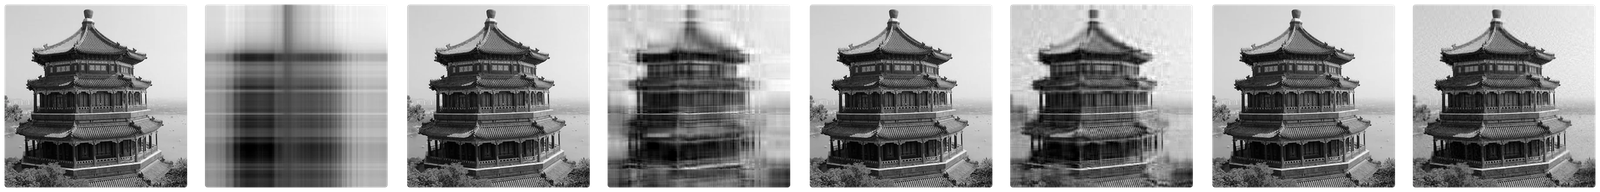

## Lưu ý khi dùng PCA

- **Chuẩn hóa nếu đơn vị khác nhau.** Không chuẩn hóa thì một cột đo bằng đồng sẽ “nuốt” toàn bộ phương sai và thành phần chính chỉ là cột đó. Dời cả bảng đi một hằng số không đổi gì, vì PCA trừ trung bình trước; nhưng nhân riêng một cột với hằng số là đổi phương sai của cột đó và đổi các thành phần chính.
- **PCA không biết nhãn.** Hướng phương sai nhỏ có thể lại là hướng phân biệt các lớp (hình dưới). Giảm chiều quá tay trước khi phân loại có thể làm mất đúng thông tin cần thiết.
- **Fit PCA trên train**, rồi biến đổi validation và test bằng cùng phép chiếu, như mọi bước tiền xử lý khác (bài 1.4).
- Với dữ liệu thưa như TF-IDF, dùng `TruncatedSVD` thay cho PCA để không phải trừ trung bình làm mất tính thưa. Kỹ thuật này có tên là latent semantic analysis.



**Hỏi nhanh.** Hai lớp chỉ khác nhau ở một cột có biến thiên rất nhỏ. Cột còn lại là nhiễu, biên độ lớn. PCA không dùng nhãn sẽ ưu tiên giữ hướng nào?

- A. Hướng có phương sai lớn, dù với bài này đó là nhiễu
- B. Hướng chứa thông tin về nhãn, vì nó tách hai lớp rõ nhất
- C. Cả hai hướng, vì PCA giữ mọi thông tin
- D. Một hướng ngẫu nhiên, tùy seed của thuật toán

<details><summary>Đáp án</summary>

A. Hướng có phương sai lớn, dù với bài này đó là nhiễu

PCA tìm cách tái tạo dữ liệu tốt nhất, chứ không trực tiếp tìm accuracy cao nhất. Vì vậy số chiều giữ lại phải được chọn theo validation của bài toán dùng sau đó.

</details>

**Hỏi nhanh.** Có hai cột: thu nhập tính bằng đồng, độ lệch chuẩn cỡ $10^7$, và tuổi, độ lệch chuẩn cỡ 10. Chạy PCA mà không chuẩn hóa. PC1 gần như là hướng nào?

- A. Trung bình cộng của hai cột
- B. Gần như trùng với trục thu nhập
- C. Gần như trùng với trục tuổi
- D. Đường chéo $45^\circ$ giữa hai cột

<details><summary>Đáp án</summary>

B. Gần như trùng với trục thu nhập

Phương sai của thu nhập lớn hơn của tuổi cỡ $10^{12}$ lần, nên hướng trải rộng nhất gần như là trục thu nhập. Con số “giữ 99.99% phương sai” lúc này chỉ phản ánh đơn vị đồng. Phải chuẩn hóa trước thì PC1 mới nói lên quan hệ giữa hai cột.

</details>

## t-SNE và UMAP: để nhìn, không phải để đo

PCA là phép chiếu tuyến tính, nên không “duỗi” được dữ liệu nằm trên mặt cong. t-SNE và UMAP là các phương pháp phi tuyến, cố giữ **láng giềng gần** của mỗi điểm khi đưa xuống 2 chiều. Chúng cho những hình rất đẹp: các cụm tách bạch rõ ràng. Nhưng đọc hình phải cẩn thận:

- Kích thước cụm và khoảng cách giữa các cụm trên hình gần như không mang ý nghĩa.
- Kết quả phụ thuộc tham số (`perplexity` của t-SNE, `n_neighbors` của UMAP) và seed ngẫu nhiên. Chạy vài cấu hình trước khi kết luận.
- Triển khai t-SNE trong scikit-learn không có transform cho điểm mới, nên không dùng làm đặc trưng cho train/test. UMAP thì có `transform`, nhưng vẫn nên ưu tiên PCA khi cần đặc trưng ổn định.

**Hỏi nhanh.** Trên hình t-SNE, cụm A nằm rất xa cụm B, còn A thì sát C. Ta được phép kết luận gì?

- A. Chỉ quan hệ láng giềng bên trong cụm là đáng tin
- B. Trong không gian gốc, A gần C hơn hẳn so với B
- C. Cụm A to gấp đôi cụm C nên có gấp đôi số điểm
- D. Phải có đúng ba lớp, vì hình có ba cụm

<details><summary>Đáp án</summary>

A. Chỉ quan hệ láng giềng bên trong cụm là đáng tin

t-SNE cố giữ các láng giềng gần của từng điểm. Khoảng cách giữa các cụm và kích thước cụm trên hình gần như không mang thông tin. Muốn so A với B và C, hãy đo trong không gian gốc hoặc trên PCA, và thử vài giá trị `perplexity`, vài seed.

</details>

| | PCA | t-SNE | UMAP |
|---|---|---|---|
| Loại | Tuyến tính | Phi tuyến | Phi tuyến |
| Giữ | Cấu trúc toàn cục, phương sai | Láng giềng gần | Láng giềng gần, phần nào cấu trúc toàn cục |
| Áp lên điểm mới | Có | Không | Có |
| Dùng chủ yếu để | Tiền xử lý, nén, khử nhiễu | Trực quan hóa | Trực quan hóa, đôi khi làm đặc trưng |



## Tự cài PCA bằng NumPy

Với `X` có $n$ hàng, $d$ cột, các bước kèm shape:

1. Trừ trung bình từng cột (vector shape `(d,)`) để dữ liệu có tâm ở 0, được `X_centered`.
2. SVD của `X_centered` với `full_matrices=False` cho `U`, `s`, `Vt`. Hàng đầu của `Vt` là PC1, shape `(d,)`.
3. Giữ $k$ hướng: `Vt[:k].T` có shape `(d, k)`. Nhân `X_centered` với nó, mỗi mẫu còn $k$ tọa độ.
4. Tái tạo: nhân tọa độ với ma trận chuyển vị, rồi cộng lại trung bình.

Code dưới chạy trên bốn điểm ở mục PCA và đối chiếu với scikit-learn.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA

X_pca = np.array([[-2., -1.], [-1., -1.], [1., 1.], [2., 1.]])
center = X_pca.mean(axis=0)
X_centered = X_pca - center
U, s, Vt = np.linalg.svd(X_centered, full_matrices=False)
components = Vt[:1].T
coordinates = X_centered @ components
reconstructed = coordinates @ components.T + center
ratio = s[0] ** 2 / np.sum(s ** 2)
library = PCA(n_components=1).fit(X_pca)
print("shape:", components.shape, coordinates.shape, reconstructed.shape)
print("tỉ lệ:", round(float(ratio), 4))
print("MSE tái tạo:", round(float(np.mean((reconstructed - X_pca) ** 2)), 6))
print("khớp tái tạo:", np.allclose(reconstructed, library.inverse_transform(library.transform(X_pca))))

shape: (2, 1) (4, 1) (4, 2)
tỉ lệ: 0.9792
MSE tái tạo: 0.036475
khớp tái tạo: True


Hai điểm hay bị tưởng là lỗi:

- **Dấu ngược.** SVD có thể cho $-\mathbf u$ thay vì $\mathbf u$. Hai vector mô tả cùng một đường: tọa độ đổi dấu nhưng dữ liệu tái tạo không đổi. Vì vậy so hai cách cài PCA bằng dữ liệu tái tạo, không so từng hệ số.
- **Mẫu số $n - 1$.** scikit-learn tính phương sai với mẫu số $n-1$, bài này dùng $n$. Tỉ lệ giữ lại không đổi vì mọi trị riêng cùng nhân một hệ số.

## Dùng thư viện

In [ ]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)          # 1797 ảnh 8×8 = 64 chiều
for name, data in [("thô", X), ("chuẩn hóa", StandardScaler().fit_transform(X))]:
    pca = PCA().fit(data)
    k = np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1
    print(f"{name}: cần {k} trên 64 thành phần để giữ 95% phương sai")

thô: cần 29 trên 64 thành phần để giữ 95% phương sai
chuẩn hóa: cần 40 trên 64 thành phần để giữ 95% phương sai


Chuẩn hóa làm cần **nhiều** thành phần hơn. Các pixel ở viền ảnh gần như luôn trắng, phương sai rất nhỏ; chuẩn hóa chia chúng cho độ lệch chuẩn bé xíu nên chúng thành những chiều có phương sai 1, ngang các pixel giữa ảnh chứa nét chữ. Ở ảnh, các pixel đã cùng đơn vị, nên chuẩn hóa không bắt buộc và cần kiểm bằng validation.

Ví dụ này cũng cho thấy “giữ 95% phương sai” là 95% tổng phương sai **theo thang đo đang dùng**: đổi thang thì con số đổi. Nó không phải 95% thông tin về nhãn, và không bảo đảm accuracy còn 95%.



**Hỏi nhanh.** Với bộ digits, dữ liệu thô cần 29 thành phần để giữ 95% phương sai, còn dữ liệu đã chuẩn hóa cần tới 40. Vì sao chuẩn hóa lại cần nhiều hơn?

- A. Chuẩn hóa làm mất thông tin, nên phải bù thêm chiều
- B. Các pixel ở viền gần như không đổi bị đẩy lên phương sai 1
- C. Chuẩn hóa làm dữ liệu thưa hơn nên khó nén
- D. Đó là sai số ngẫu nhiên của thuật toán SVD

<details><summary>Đáp án</summary>

B. Các pixel ở viền gần như không đổi bị đẩy lên phương sai 1

Sau khi chuẩn hóa, pixel nào cũng có phương sai 1, kể cả những pixel ở viền gần như không đổi. Tổng phương sai trải đều hơn trên 64 chiều, nên phải giữ nhiều thành phần hơn mới đủ 95%. Con số 95% luôn gắn với thang đo đang dùng.

</details>

## Khi đi thi

- Fit scaler và PCA trên train của từng fold, rồi transform phần còn lại.
- Embedding hàng nghìn chiều thì thử PCA xuống vài trăm chiều; chỉ giữ nếu validation không tụt.
- Dùng t-SNE, UMAP để nhìn, không đưa tọa độ của chúng làm feature.

## Tóm tắt

- PCA chiếu dữ liệu lên các hướng có phương sai lớn nhất, chính là các vector riêng của ma trận hiệp phương sai; tính bằng SVD.
- Tỉ lệ phương sai giữ lại giúp chọn số chiều; chuẩn hóa trước khi đơn vị khác nhau; fit trên train.
- PCA không dùng nhãn, nên có thể bỏ mất hướng phân biệt lớp.
- t-SNE, UMAP dùng để nhìn cấu trúc láng giềng; không đọc khoảng cách giữa cụm, không dùng t-SNE làm đặc trưng.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** PCA fit trên `X_train` có shape `(120, 7)` và giữ 3 thành phần. Transform `X_valid` có shape `(40, 7)` thì đầu ra có shape gì?

- A. `(3, 40)`
- B. `(40, 7)`
- C. `(40, 3)`
- D. `(120, 3)`

<details><summary>Đáp án</summary>

C. `(40, 3)`

Số hàng theo dữ liệu đang transform, số cột theo `n_components` đã học. PCA không bắt validation phải có cùng số mẫu với train.

</details>
**Câu 2.** Tự cài PCA bằng SVD. Với `X` có shape `(n, d)`, dòng nào trừ trung bình đúng cho từng feature?

- A. `X - X.mean(axis=1, keepdims=True)`
- B. `X - X.mean()`
- C. `X / X.std(axis=0, keepdims=True)`
- D. `X - X.mean(axis=0, keepdims=True)`

<details><summary>Đáp án</summary>

D. `X - X.mean(axis=0, keepdims=True)`

PCA thông thường trừ trung bình của từng cột. Trừ trung bình từng mẫu, trừ trung bình cả bảng, hay chỉ chia cho độ lệch chuẩn là ba phép biến đổi khác.

</details>
**Câu 3.** PCA có ba trị riêng là 6, 3 và 1. Giữ hai thành phần đầu thì giữ được bao nhiêu phần phương sai?

- A. 0.9
- B. 0.6
- C. 0.3
- D. 0.95

<details><summary>Đáp án</summary>

A. 0.9

$(6 + 3)/(6 + 3 + 1) = 0.9$. Ra 0.6 là chỉ tính PC1. Ra 0.3 là tỉ lệ của riêng PC2.

</details>
**Câu 4.** Với $v = (1, -2, 3)$, vector đơn vị cùng hướng với $v$ là gì?

- A. $v/14$
- B. $-v/\sqrt{14}$
- C. $v/\sqrt{14}$
- D. $v/\sqrt{6}$

<details><summary>Đáp án</summary>

C. $v/\sqrt{14}$

Độ dài của $v$ là $\sqrt{1 + 4 + 9} = \sqrt{14}$. Chia cho độ dài thì giữ nguyên hướng, còn đổi dấu cả vector là thành hướng ngược lại. Mỗi thành phần chính trong PCA đều là một vector đơn vị như vậy.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 2.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=4)

</details>
**Câu 5.** Trên cùng các fold, hai cấu hình PCA giữ 95% và 99% phương sai có accuracy validation lần lượt là 0.88 và 0.84. Ta chọn theo accuracy. Kết luận nào đúng?

- A. Accuracy 0.84 là sai, vì ít nhất phải bằng 0.99
- B. Hai cấu hình như nhau, vì đều giữ trên 90% phương sai
- C. Chọn 95%, vì giữ nhiều phương sai hơn chưa chắc giúp phân loại
- D. Chọn 99%, vì accuracy phải tăng theo tỉ lệ phương sai giữ lại

<details><summary>Đáp án</summary>

C. Chọn 95%, vì giữ nhiều phương sai hơn chưa chắc giúp phân loại

Phương sai mô tả $X$, không trực tiếp nói gì về tín hiệu cho $y$. Ta quyết định dựa trên kết quả đánh giá của bài toán sau PCA.

</details>
**Câu 6.** Code fit PCA trên toàn bộ `X_dev`, rồi mới chạy `cross_val_score` cho classifier. Sửa thế nào để PCA không học thống kê từ fold validation?

- A. Đưa PCA và classifier vào một Pipeline, rồi chạy CV trên `X_dev` gốc
- B. Fit PCA riêng trên từng fold validation rồi mới dự đoán
- C. Chỉ cần bỏ `y` ra khi fit PCA trên toàn `X_dev`
- D. Giữ PCA đã fit, chỉ đổi `random_state` của classifier

<details><summary>Đáp án</summary>

A. Đưa PCA và classifier vào một Pipeline, rồi chạy CV trên `X_dev` gốc

Không dùng nhãn không có nghĩa là không học gì từ dữ liệu. PCA phải fit trên phần train của từng fold, rồi dùng đúng phép chiếu ấy cho phần validation.

</details>
**Câu 7.** Ma trận hiệp phương sai chia cho $n$ hay $n - 1$ thì tỉ lệ phương sai giữ lại có đổi không?

- A. Có, vì mọi trị riêng đều đổi
- B. Không, vì hệ số chung bị triệt tiêu
- C. Chỉ đổi khi dữ liệu có một cột
- D. Không tính được nếu chia cho $n - 1$

<details><summary>Đáp án</summary>

B. Không, vì hệ số chung bị triệt tiêu

Mọi trị riêng cùng nhân với một hệ số, và hệ số chung ấy triệt tiêu khi chia cho tổng các trị riêng.

</details>
**Câu 8.** Mặc định, `TruncatedSVD` trên ma trận TF-IDF có trừ trung bình như PCA không?

- A. Có, giống hệt PCA thông thường
- B. Chỉ trừ trung bình ở cột target
- C. Chỉ khi `n_components=2`
- D. Không, để giữ ma trận ở dạng thưa

<details><summary>Đáp án</summary>

D. Không, để giữ ma trận ở dạng thưa

Trừ trung bình biến hầu hết các số 0 thành khác 0, nên ma trận thưa thành ma trận dày và tràn bộ nhớ. `TruncatedSVD` phân rã ma trận mà không trừ trung bình, nên kết quả không trùng với PCA.

</details>
**Câu 9.** UMAP vẽ một bản đồ 2 chiều cho các embedding. Khi đọc khoảng cách trên hình, câu nào đúng với điều UMAP ưu tiên?

- A. Mọi khoảng cách giữa hai điểm trong không gian gốc được giữ đúng tỉ lệ
- B. Phép chiếu luôn tuyến tính, nên đổi seed không làm đổi hình
- C. Nó tìm lỗi tái tạo nhỏ nhất, giống PCA
- D. Nó ưu tiên giữ láng giềng gần hơn là khoảng cách toàn cục

<details><summary>Đáp án</summary>

D. Nó ưu tiên giữ láng giềng gần hơn là khoảng cách toàn cục

Hình giúp ta khảo sát cấu trúc lân cận. Khoảng cách toàn cục và khoảng cách giữa các cụm thì phải đọc thận trọng, và kiểm lại với vài tham số, vài seed. UMAP là phép chiếu phi tuyến, và mục tiêu của nó không phải lỗi tái tạo.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 1.5](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=3)

</details>
**Câu 10.** PCA tự cài cho một thành phần đúng bằng âm của thành phần mà thư viện cho, còn trị riêng và trung bình thì khớp. Đối chiếu thế nào để kiểm đúng phép chiếu, thay vì chỉ so hướng?

- A. So ma trận chiếu, hoặc so dữ liệu tái tạo
- B. Kết luận là sai, vì thành phần phải giống đến từng số
- C. Đổi mọi phần tử âm của thành phần thành dương
- D. Chỉ so tổng các tọa độ PCA của từng mẫu

<details><summary>Đáp án</summary>

A. So ma trận chiếu, hoặc so dữ liệu tái tạo

$\mathbf v$ và $-\mathbf v$ cho cùng một phép chiếu $\mathbf v\mathbf v^\top$. Tọa độ cũng đổi dấu theo, nên dữ liệu tái tạo vẫn y như cũ. Đổi dấu từng phần tử riêng lẻ thì không phải là đổi hướng cả vector.

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 12. PCA từ góc nhìn thống kê, kèm cách đọc explained variance.
- Géron — *Hands-On Machine Learning*, chương 8. PCA, randomized PCA và các phương pháp giảm chiều khác trong scikit-learn.
- van der Maaten, Hinton (2008) — *Visualizing Data using t-SNE*; McInnes và cộng sự (2018) — [*UMAP*](https://arxiv.org/abs/1802.03426). Bài gốc của hai phương pháp trực quan hóa.

- [scikit-learn — PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca). Centering, SVD, explained variance và quan hệ với sparse data.
- [Distill — How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/). Các thí nghiệm trực quan giúp tránh đọc quá mức hình t-SNE.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).